# 반도체만 날았나? — 반도체 vs 비반도체 제조업 생산지수 시계열 분석

- 데이터: 통계청 KOSIS 광업제조업동향조사 「기타분류별 광공업생산지수(2020=100)」
- 기간: 2017.01 ~ 2026.07 (월별 115개, 2026.06~07은 잠정치)
- 비교: **반도체 및 부품(C26A)** vs **반도체 및 부품 제외 제조업**

위에서부터 순서대로 실행하면 `data/clean_production.csv`와 `images/*.png`가 만들어진다.

## 0. 준비 — 라이브러리, 한글 폰트, 색상

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

# 한글 폰트 (Windows: 맑은 고딕, macOS: AppleGothic)
plt.rcParams['font.family'] = 'Malgun Gothic' if platform.system() == 'Windows' else 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'axes.edgecolor': '#9a9994',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'legend.frameon': False,
})

SEMI, NONSEMI, MUTED = '#2a78d6', '#eb6834', '#8a8984'   # 반도체=파랑, 비반도체=주황, 보조=회색
RAW = Path('data/raw/kosis_production_index_2017_2026.xlsx')
IMG = Path('images'); IMG.mkdir(exist_ok=True)

## 1. 데이터 불러오기와 기본 정보 확인

KOSIS 엑셀은 **가로로 넓은 형태**다. 1행은 날짜(한 달에 3칸: 생산·출하·재고), 2행은 지표 이름, 3행부터 산업이다.
분석하기 쉽게 **세로(날짜가 행) 형태**로 바꾼다.

사용할 행
- `반도체 및 부품(C26A)` — 반도체 + 전자부품 (생산·출하·재고)
- `반도체 및 부품 제외 → 제조업` — 같은 기준(C26A)으로 뺀 나머지 제조업. 비교 기준을 맞추기 위해 'C261 제외'가 아닌 'C26A 제외'를 쓴다.

In [2]:
raw = pd.read_excel(RAW, header=None)
print('원본 크기:', raw.shape)

months = raw.iloc[0, 2:].astype(str).tolist()
metrics = raw.iloc[1, 2:].astype(str).tolist()
label = raw.iloc[:, 0].ffill().astype(str) + ' | ' + raw.iloc[:, 1].astype(str)

def pick(row_label, metric_word):
    """행 이름과 지표(생산/출하/재고)로 시계열 1개를 뽑는다."""
    r = label[label == row_label].index[0]
    cols = [i for i, m in enumerate(metrics) if metric_word in m]
    s = pd.Series(raw.iloc[r, 2:].values[cols], index=[months[i] for i in cols])
    return s

semi_key = '반도체 및 부품(C261+C262=C26A) | 반도체 및 부품'
non_key = '반도체 및 부품 제외(C26A제외) | 제조업'
df = pd.DataFrame({
    'semi_prod': pick(semi_key, '산업생산'),
    'semi_ship': pick(semi_key, '출하'),
    'semi_inv':  pick(semi_key, '재고'),
    'nonsemi_prod': pick(non_key, '산업생산'),
})
df.index.name = 'month_raw'
df.head()

원본 크기: (35, 347)


C:\Users\04121\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,semi_prod,semi_ship,semi_inv,nonsemi_prod
month_raw,,,,
2017.01,68.797,70.038,99.307,100.953
2017.02,62.057,66.182,94.158,101.271
2017.03,70.308,75.917,88.713,115.148
2017.04,64.323,68.963,94.95,109.428
2017.05,71.121,73.388,106.238,108.369


### 1-1. 날짜 정리와 잠정치 표시
`2026.07 p)`처럼 잠정치 표시(p)가 붙은 달이 있다. 날짜로 바꾸고, 잠정치 여부는 별도 열에 남긴다.

In [3]:
df = df.reset_index()
df['is_preliminary'] = df['month_raw'].str.contains('p')
df['date'] = pd.to_datetime(df['month_raw'].str.extract(r'(\d{4}\.\d{2})')[0], format='%Y.%m')
df = df.set_index('date').drop(columns='month_raw').sort_index()

num_cols = ['semi_prod', 'semi_ship', 'semi_inv', 'nonsemi_prod']
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')   # '-' 같은 값은 NaN이 된다

print('기간:', df.index.min().strftime('%Y-%m'), '~', df.index.max().strftime('%Y-%m'))
print('데이터 포인트(월):', len(df))
print('잠정치 달:', df.index[df['is_preliminary']].strftime('%Y-%m').tolist())
expected = pd.date_range(df.index.min(), df.index.max(), freq='MS')
print('빠진 달:', len(expected.difference(df.index)), '개')
df.info()

기간: 2017-01 ~ 2026-07
데이터 포인트(월): 115
잠정치 달: ['2026-06', '2026-07']
빠진 달: 0 개
<class 'pandas.DataFrame'>
DatetimeIndex: 115 entries, 2017-01-01 to 2026-07-01
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   semi_prod       115 non-null    float64
 1   semi_ship       115 non-null    float64
 2   semi_inv        115 non-null    float64
 3   nonsemi_prod    115 non-null    float64
 4   is_preliminary  115 non-null    bool   
dtypes: bool(1), float64(4)
memory usage: 4.6 KB


### 1-2. 결측치 확인

In [4]:
print(df[num_cols].isna().sum())
df[num_cols].describe().round(1)

semi_prod       0
semi_ship       0
semi_inv        0
nonsemi_prod    0
dtype: int64


,semi_prod,semi_ship,semi_inv,nonsemi_prod
count,115.0,115.0,115.0,115.0
mean,111.6,104.3,115.5,105.1
std,28.2,22.4,26.0,5.8
min,62.1,66.2,81.0,87.7
25%,86.7,87.1,97.6,102.0
50%,111.2,100.7,107.9,105.9
75%,133.0,117.8,124.2,108.9
max,178.6,164.1,208.2,115.8


**결측치 처리 기준:** 숫자로 바뀌지 않는 값은 NaN으로 바꾸고 개수를 센다. 확인 결과 결측치와 빠진 달이 **0개**라서 채우거나 지울 값이 없다.
(있었다면 '앞뒤 달 평균으로 보간'을 쓰고 리포트에 적을 계획이었다.)

## 2. 파생 지표 만들기 — 분석 기법
| 기법 | 왜 쓰나 |
|---|---|
| 12개월 이동평균(MA12) | 원지수는 계절 요동(설·추석, 연말)이 크다. 12개월 평균이면 한 해의 계절 효과가 상쇄되어 **추세**만 남는다 |
| 전년동월대비 증가율(YoY) | 같은 달끼리 비교하므로 **계절성이 제거된 성장 속도**를 본다 |
| 롤링 12개월 표준편차 | YoY가 얼마나 출렁이는지 = **변동성** |
| 반도체/비반도체 비율 | 두 산업의 **격차**를 숫자 하나로 본다 |

In [5]:
for c in ['semi_prod', 'nonsemi_prod', 'semi_inv', 'semi_ship']:
    df[f'{c}_ma12'] = df[c].rolling(12).mean()
    df[f'{c}_yoy'] = df[c].pct_change(12, fill_method=None) * 100
for c in ['semi_prod', 'nonsemi_prod']:
    df[f'{c}_vol12'] = df[f'{c}_yoy'].rolling(12).std()
df['gap_ratio'] = df['semi_prod_ma12'] / df['nonsemi_prod_ma12']
df['semi_inv_ship_ratio'] = df['semi_inv'] / df['semi_ship'] * 100   # 재고/출하 비율

df[['semi_prod', 'semi_prod_ma12', 'semi_prod_yoy', 'nonsemi_prod_yoy']].tail(6).round(1)

,semi_prod,semi_prod_ma12,semi_prod_yoy,nonsemi_prod_yoy
date,,,,
2026-02-01,150.6,151.2,22.4,-9.0
2026-03-01,165.4,152.1,6.9,3.4
2026-04-01,151.1,153.3,11.2,-1.7
2026-05-01,148.7,153.5,1.1,-2.0
2026-06-01,162.8,153.8,2.8,7.5
2026-07-01,154.6,154.1,2.0,4.6


## 3. 이상치 확인
**기준:** YoY 증가율이 해당 산업 평균 ± 3표준편차를 벗어나면 이상치 후보로 **표시만** 한다.
반도체의 급등락은 입력 오류가 아니라 이 분석이 보려는 현상 자체이므로 **삭제하지 않는다**.
원자료 오류 여부는 같은 달 출하지수가 같은 방향으로 움직였는지로 교차 확인한다.

In [6]:
outliers = []
for c in ['semi_prod_yoy', 'nonsemi_prod_yoy']:
    s = df[c].dropna()
    z = (s - s.mean()) / s.std()
    flagged = s[z.abs() > 3]
    print(f'{c}: 평균 {s.mean():.1f}%, 표준편차 {s.std():.1f}%p, 이상치 후보 {len(flagged)}개')
    for d, v in flagged.items():
        print(f'   {d:%Y-%m}  YoY {v:+.1f}%  (같은 달 반도체 출하 YoY {df.loc[d, "semi_ship_yoy"]:+.1f}%)')
        outliers.append((c, d))

semi_prod_yoy: 평균 10.4%, 표준편차 15.1%p, 이상치 후보 1개
   2023-02  YoY -37.6%  (같은 달 반도체 출하 YoY -33.2%)
nonsemi_prod_yoy: 평균 0.2%, 표준편차 5.4%p, 이상치 후보 1개
   2020-05  YoY -16.1%  (같은 달 반도체 출하 YoY +6.4%)


## 4. 국면(구간) 나누기
반도체 업황 뉴스와 지수의 꺾임을 기준으로 7개 구간을 **사전에 정한다**(구간 경계는 분석자의 판단이며 한계점에 적는다).

In [7]:
phases = [
    ('2017-01', '2018-12', '① 메모리 슈퍼사이클'),
    ('2019-01', '2019-12', '② 다운사이클'),
    ('2020-01', '2020-12', '③ 코로나'),
    ('2021-01', '2022-06', '④ 비대면 특수'),
    ('2022-07', '2023-06', '⑤ 반도체 불황'),
    ('2023-07', '2024-12', '⑥ 회복'),
    ('2025-01', '2026-07', '⑦ AI·HBM 호황'),
]
rows = []
for s, e, name in phases:
    seg = df.loc[s:e]
    rows.append({
        '국면': name, '기간': f'{s}~{e}', '개월': len(seg),
        '반도체 평균 YoY(%)': seg['semi_prod_yoy'].mean(),
        '비반도체 평균 YoY(%)': seg['nonsemi_prod_yoy'].mean(),
        '반도체 YoY 표준편차': seg['semi_prod_yoy'].std(),
        '비반도체 YoY 표준편차': seg['nonsemi_prod_yoy'].std(),
        '반도체 평균 지수': seg['semi_prod'].mean(),
        '비반도체 평균 지수': seg['nonsemi_prod'].mean(),
    })
phase_tbl = pd.DataFrame(rows).set_index('국면')
phase_tbl.round(1)

,기간,개월,반도체 평균 YoY(%),비반도체 평균 YoY(%),반도체 YoY 표준편차,비반도체 YoY 표준편차,반도체 평균 지수,비반도체 평균 지수
국면,,,,,,,,
① 메모리 슈퍼사이클,2017-01~2018-12,24,14.8,-1.7,7.5,6.3,77.5,105.8
② 다운사이클,2019-01~2019-12,12,5.6,-1.1,8.3,2.5,87.5,103.7
③ 코로나,2020-01~2020-12,12,14.7,-3.4,6.8,6.7,100.0,100.0
④ 비대면 특수,2021-01~2022-06,18,20.6,3.9,4.3,5.1,124.0,105.5
⑤ 반도체 불황,2022-07~2023-06,12,-20.2,0.3,10.2,3.6,105.2,105.8
⑥ 회복,2023-07~2024-12,18,18.7,0.2,14.0,3.9,132.4,105.5
⑦ AI·HBM 호황,2025-01~2026-07,19,9.5,1.0,8.6,5.8,150.1,107.1


※ 2017년은 전년 자료가 없어 YoY를 계산할 수 없으므로 ① 국면의 YoY 통계는 2018년 12개월만으로 계산된다.

## 5. 시각화

### 5-1. [그래프 1] 추세 — 반도체와 비반도체, 언제부터 벌어졌나

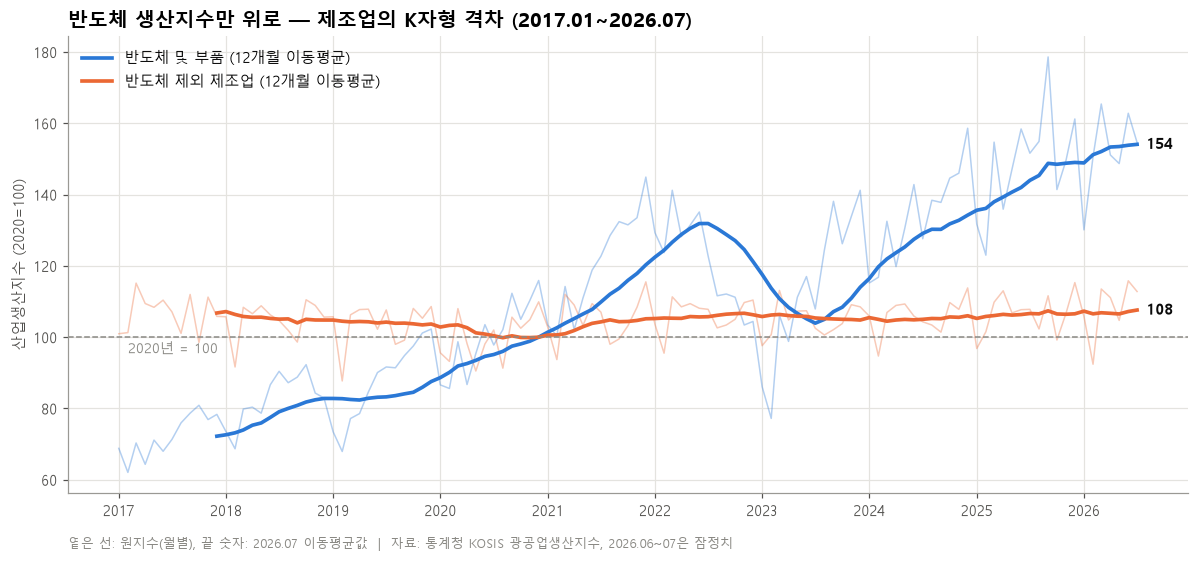

2017-12: 반도체 MA12 72.2 / 비반도체 MA12 106.8 / 격차비율 0.68
2020-12: 반도체 MA12 100.0 / 비반도체 MA12 100.0 / 격차비율 1.00
2022-06: 반도체 MA12 131.9 / 비반도체 MA12 105.7 / 격차비율 1.25
2023-06: 반도체 MA12 105.2 / 비반도체 MA12 105.8 / 격차비율 0.99
2024-12: 반도체 MA12 134.2 / 비반도체 MA12 106.0 / 격차비율 1.27
2026-07: 반도체 MA12 154.1 / 비반도체 MA12 107.6 / 격차비율 1.43


In [8]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(df.index, df['semi_prod'], color=SEMI, lw=1, alpha=0.35)
ax.plot(df.index, df['nonsemi_prod'], color=NONSEMI, lw=1, alpha=0.35)
ax.plot(df.index, df['semi_prod_ma12'], color=SEMI, lw=2.4, label='반도체 및 부품 (12개월 이동평균)')
ax.plot(df.index, df['nonsemi_prod_ma12'], color=NONSEMI, lw=2.4, label='반도체 제외 제조업 (12개월 이동평균)')
ax.axhline(100, color=MUTED, lw=1, ls='--')
ax.text(df.index[1], 95.5, '2020년 = 100', color=MUTED, fontsize=9)
last = df.index[-1]
ax.annotate(f"{df['semi_prod_ma12'].iloc[-1]:.0f}", (last, df['semi_prod_ma12'].iloc[-1]), xytext=(6, 0), textcoords='offset points', color='#0b0b0b', va='center', fontsize=10, fontweight='bold')
ax.annotate(f"{df['nonsemi_prod_ma12'].iloc[-1]:.0f}", (last, df['nonsemi_prod_ma12'].iloc[-1]), xytext=(6, 0), textcoords='offset points', color='#0b0b0b', va='center', fontsize=10, fontweight='bold')
ax.set_title('반도체 생산지수만 위로 — 제조업의 K자형 격차 (2017.01~2026.07)', loc='left')
ax.set_ylabel('산업생산지수 (2020=100)')
ax.legend(loc='upper left')
ax.text(0, -0.12, '옅은 선: 원지수(월별), 끝 숫자: 2026.07 이동평균값  |  자료: 통계청 KOSIS 광공업생산지수, 2026.06~07은 잠정치', transform=ax.transAxes, fontsize=8.5, color=MUTED)
fig.tight_layout(); fig.savefig(IMG / '01_production_trend.png', bbox_inches='tight'); plt.show()

for d in ['2017-12', '2020-12', '2022-06', '2023-06', '2024-12', '2026-07']:
    r = df.loc[d].iloc[0] if isinstance(df.loc[d], pd.DataFrame) else df.loc[d]
    print(f"{d}: 반도체 MA12 {r['semi_prod_ma12']:.1f} / 비반도체 MA12 {r['nonsemi_prod_ma12']:.1f} / 격차비율 {r['gap_ratio']:.2f}" if pd.notna(r['semi_prod_ma12']) else d)

### 5-2. [그래프 2] 성장 속도 — 전년동월대비 증가율과 국면

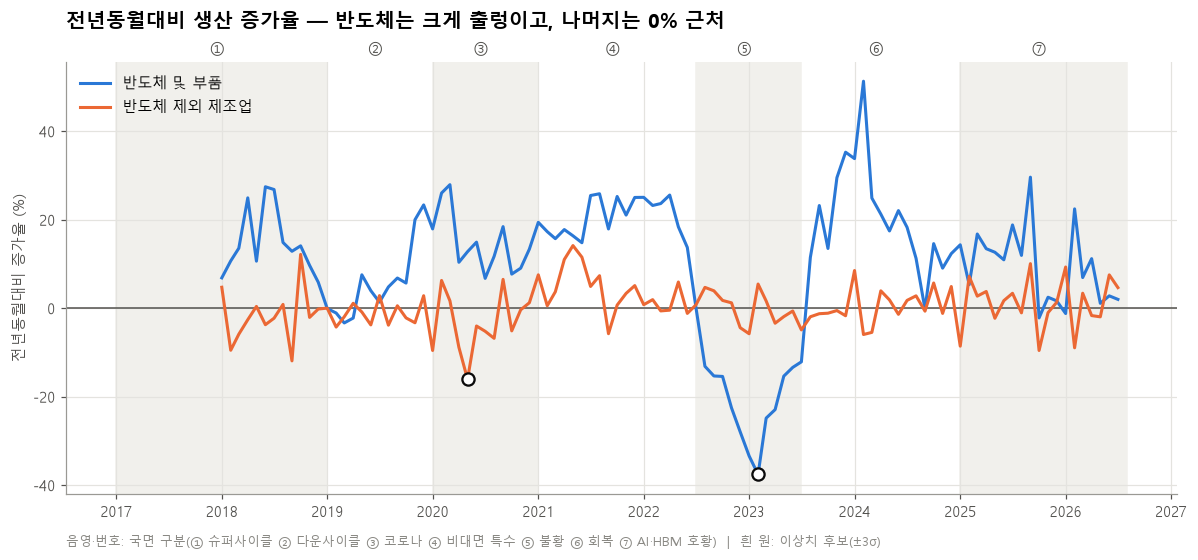

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.2))
for i, (s, e, name) in enumerate(phases):
    if i % 2 == 0:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e) + pd.offsets.MonthEnd(0), color='#f1f0ec', zorder=0)
    ax.text(pd.Timestamp(s) + (pd.Timestamp(e) - pd.Timestamp(s)) / 2, 1.02, name.split(' ')[0], transform=ax.get_xaxis_transform(), ha='center', fontsize=10, color='#52514e')
ax.axhline(0, color='#52514e', lw=1)
ax.plot(df.index, df['semi_prod_yoy'], color=SEMI, lw=2, label='반도체 및 부품')
ax.plot(df.index, df['nonsemi_prod_yoy'], color=NONSEMI, lw=2, label='반도체 제외 제조업')
for c, d in outliers:
    ax.plot(d, df.loc[d, c], 'o', ms=8, mfc='white', mec='#0b0b0b', mew=1.5, zorder=5)
ax.set_title('전년동월대비 생산 증가율 — 반도체는 크게 출렁이고, 나머지는 0% 근처', loc='left', pad=22)
ax.set_ylabel('전년동월대비 증가율 (%)')
ax.legend(loc='upper left')
ax.text(0, -0.12, '음영·번호: 국면 구분(① 슈퍼사이클 ② 다운사이클 ③ 코로나 ④ 비대면 특수 ⑤ 불황 ⑥ 회복 ⑦ AI·HBM 호황)  |  흰 원: 이상치 후보(±3σ)', transform=ax.transAxes, fontsize=8.5, color=MUTED)
fig.tight_layout(); fig.savefig(IMG / '02_yoy_growth.png', bbox_inches='tight'); plt.show()

### 5-3. [그래프 3] 국면별 평균 증가율과 변동성

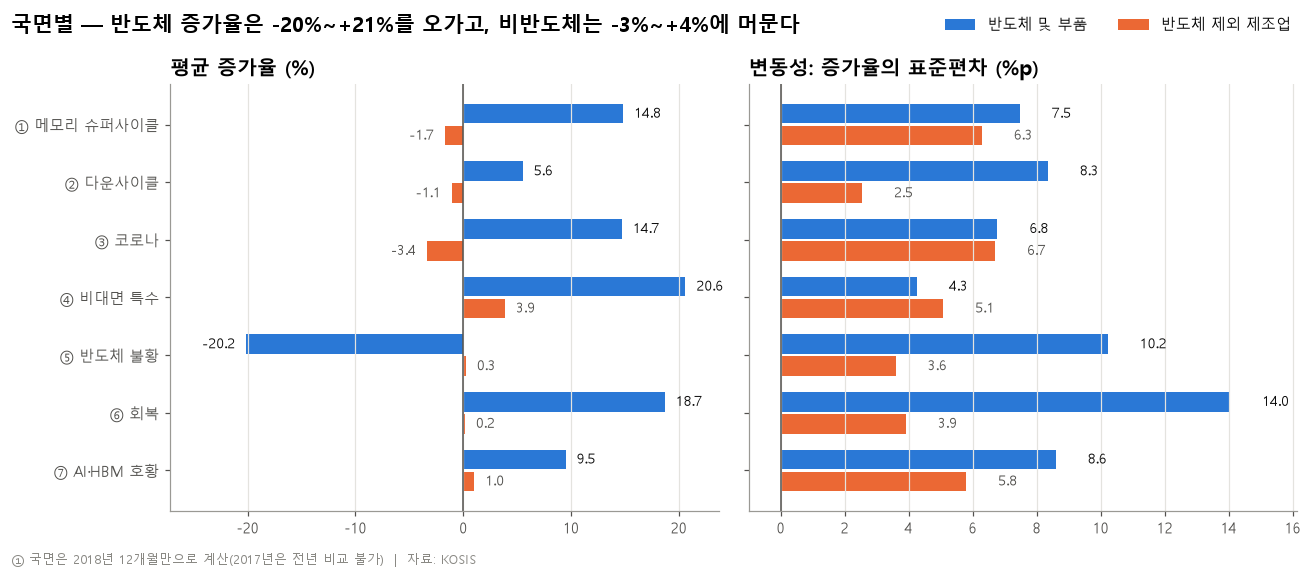

In [10]:
t = phase_tbl
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
y = np.arange(len(t)); h = 0.38
for ax, (a, b, title) in zip(axes, [('반도체 평균 YoY(%)', '비반도체 평균 YoY(%)', '평균 증가율 (%)'),
                                    ('반도체 YoY 표준편차', '비반도체 YoY 표준편차', '변동성: 증가율의 표준편차 (%p)')]):
    ax.barh(y - h/2, t[a], height=h - 0.04, color=SEMI, label='반도체 및 부품')
    ax.barh(y + h/2, t[b], height=h - 0.04, color=NONSEMI, label='반도체 제외 제조업')
    for yy, v in zip(y - h/2, t[a]):
        ax.text(v + (1 if v >= 0 else -1), yy, f'{v:.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9, color='#0b0b0b')
    for yy, v in zip(y + h/2, t[b]):
        ax.text(v + (1 if v >= 0 else -1), yy, f'{v:.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9, color='#52514e')
    ax.axvline(0, color='#52514e', lw=1)
    ax.set_title(title, loc='left'); ax.grid(axis='y', visible=False)
    ax.set_xlim(min(0, t[[a, b]].min().min()) * 1.3 - 1, t[[a, b]].max().max() * 1.15)
axes[0].set_yticks(y, t.index); axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper right', ncol=2, bbox_to_anchor=(0.99, 1.0))
fig.suptitle('국면별 — 반도체 증가율은 -20%~+21%를 오가고, 비반도체는 -3%~+4%에 머문다', x=0.01, ha='left', fontweight='bold', fontsize=14)
fig.text(0.01, -0.02, '① 국면은 2018년 12개월만으로 계산(2017년은 전년 비교 불가)  |  자료: KOSIS', fontsize=8.5, color=MUTED)
fig.tight_layout(); fig.savefig(IMG / '03_phase_stats.png', bbox_inches='tight'); plt.show()

### 5-4. [그래프 4] 재고 사이클 — 반도체 재고가 생산보다 먼저 움직였나
재고 증가율이 생산 증가율보다 낮아지는(재고가 줄어드는) 시기를 흔히 '재고 조정 → 생산 회복' 신호로 본다.

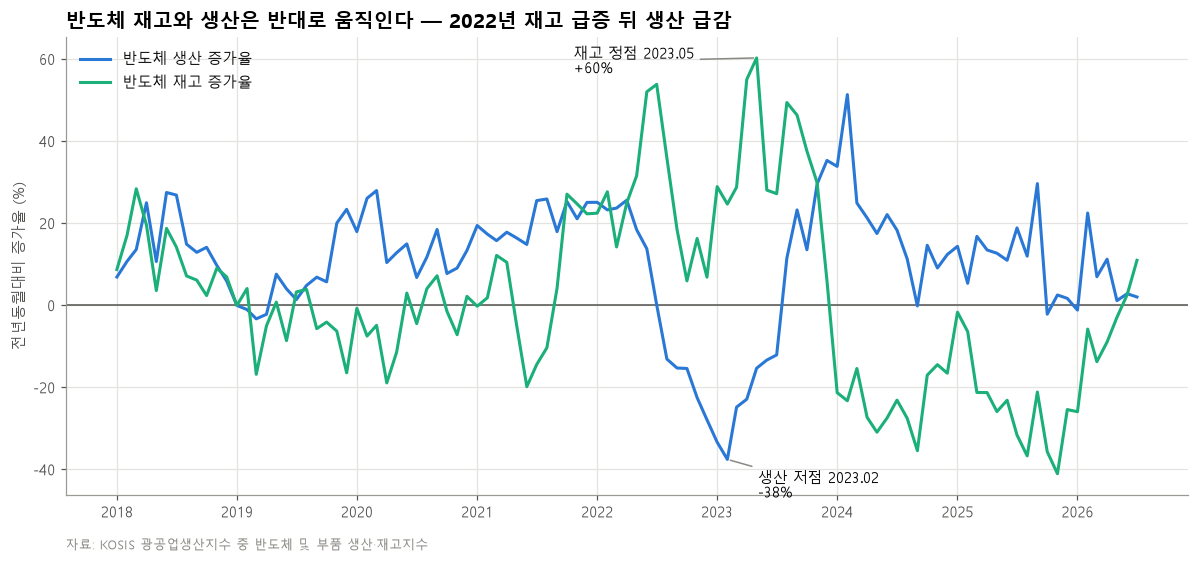

재고 증가율 정점: 2023-05 / 2022~24 생산 증가율 저점: 2023-02


In [11]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.axhline(0, color='#52514e', lw=1)
ax.plot(df.index, df['semi_prod_yoy'], color=SEMI, lw=2, label='반도체 생산 증가율')
ax.plot(df.index, df['semi_inv_yoy'], color='#1baf7a', lw=2, label='반도체 재고 증가율')
peak_inv = df['semi_inv_yoy'].idxmax(); trough_prod = df['semi_prod_yoy'].loc['2022':'2024'].idxmin()
ax.annotate(f"재고 정점 {peak_inv:%Y.%m}\n{df.loc[peak_inv, 'semi_inv_yoy']:+.0f}%", (peak_inv, df.loc[peak_inv, 'semi_inv_yoy']),
            xytext=(-120, -10), textcoords='offset points', fontsize=9.5, arrowprops=dict(arrowstyle='-', color=MUTED))
ax.annotate(f"생산 저점 {trough_prod:%Y.%m}\n{df.loc[trough_prod, 'semi_prod_yoy']:+.0f}%", (trough_prod, df.loc[trough_prod, 'semi_prod_yoy']),
            xytext=(20, -25), textcoords='offset points', fontsize=9.5, arrowprops=dict(arrowstyle='-', color=MUTED))
ax.set_title('반도체 재고와 생산은 반대로 움직인다 — 2022년 재고 급증 뒤 생산 급감', loc='left')
ax.set_ylabel('전년동월대비 증가율 (%)')
ax.legend(loc='upper left')
ax.text(0, -0.12, '자료: KOSIS 광공업생산지수 중 반도체 및 부품 생산·재고지수', transform=ax.transAxes, fontsize=8.5, color=MUTED)
fig.tight_layout(); fig.savefig(IMG / '04_inventory_cycle.png', bbox_inches='tight'); plt.show()
print('재고 증가율 정점:', f'{peak_inv:%Y-%m}', '/ 2022~24 생산 증가율 저점:', f'{trough_prod:%Y-%m}')

### 5-5. [그래프 5] 시차 상관 — 누가 먼저 움직이나
`k`개월 시차 상관 = (반도체 지표의 t월) 과 (비교 대상의 t+k월) 의 상관계수.
k가 양수에서 가장 크면 "반도체가 k개월 **앞서** 움직인다"는 뜻이다. **상관이지 인과가 아니다.**

                     -6    -5    -4    -3    -2    -1     0     1     2     3  \
반도체 생산 vs 비반도체 생산 -0.00  0.00 -0.11  0.04  0.03  0.07  0.08  0.03  0.04  0.08   
반도체 재고 vs 반도체 생산  -0.39 -0.43 -0.45 -0.40 -0.38 -0.33 -0.25 -0.25 -0.20 -0.12   

                      4     5     6  
반도체 생산 vs 비반도체 생산  0.23  0.04  0.11  
반도체 재고 vs 반도체 생산  -0.08 -0.09 -0.12  


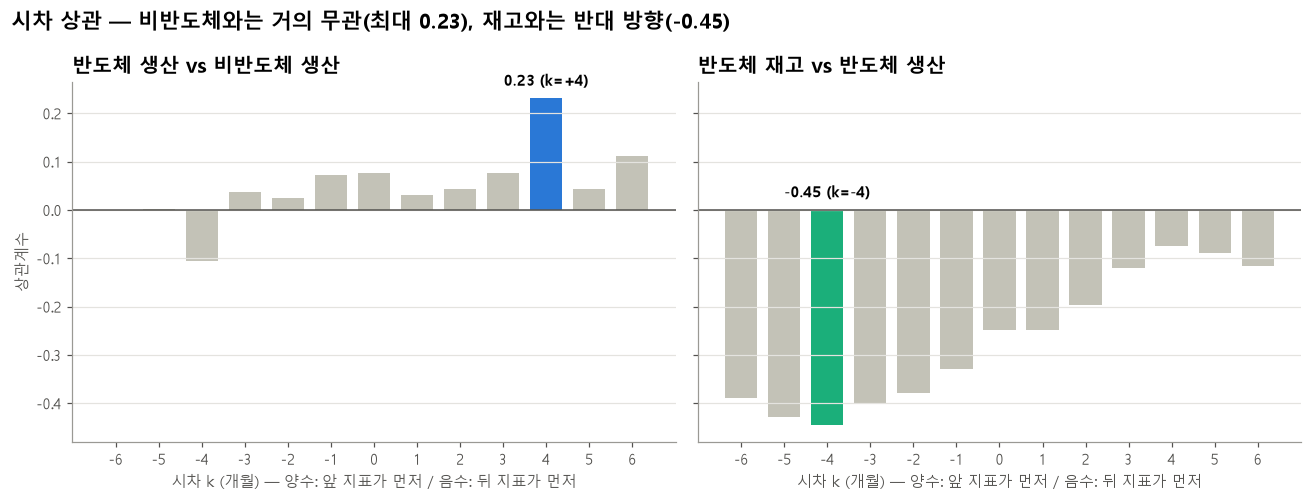

In [12]:
lags = range(-6, 7)
def lag_corr(x, y, k):
    return df[x].corr(df[y].shift(-k))
lc = pd.DataFrame({
    '반도체 생산 vs 비반도체 생산': [lag_corr('semi_prod_yoy', 'nonsemi_prod_yoy', k) for k in lags],
    '반도체 재고 vs 반도체 생산': [lag_corr('semi_inv_yoy', 'semi_prod_yoy', k) for k in lags],
}, index=list(lags))
print(lc.round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, col, color in zip(axes, lc.columns, [SEMI, '#1baf7a']):
    best = lc[col].abs().idxmax()
    ax.bar(lc.index, lc[col], color=[color if k == best else '#c3c2b7' for k in lc.index], width=0.75)
    ax.axhline(0, color='#52514e', lw=1)
    v = lc.loc[best, col]
    ax.text(best, v + 0.02 if v >= 0 else 0.02, f'{v:.2f} (k={best:+d})', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.set_title(col, loc='left'); ax.set_xlabel('시차 k (개월) — 양수: 앞 지표가 먼저 / 음수: 뒤 지표가 먼저'); ax.grid(axis='x', visible=False)
    ax.set_xticks(list(lags))
axes[0].set_ylabel('상관계수')
fig.suptitle('시차 상관 — 비반도체와는 거의 무관(최대 0.23), 재고와는 반대 방향(-0.45)', x=0.01, ha='left', fontweight='bold', fontsize=14)
fig.tight_layout(); fig.savefig(IMG / '05_lag_correlation.png', bbox_inches='tight'); plt.show()

## 6. [보너스 A] 시계열 분해 — 추세 / 계절성 / 잔차
STL 분해(주기 12개월)로 반도체 생산지수 원지수를 세 부분으로 나눈다.
- **추세**: 장기 흐름  - **계절성**: 매년 반복되는 월별 패턴  - **잔차(노이즈)**: 둘로 설명되지 않는 나머지

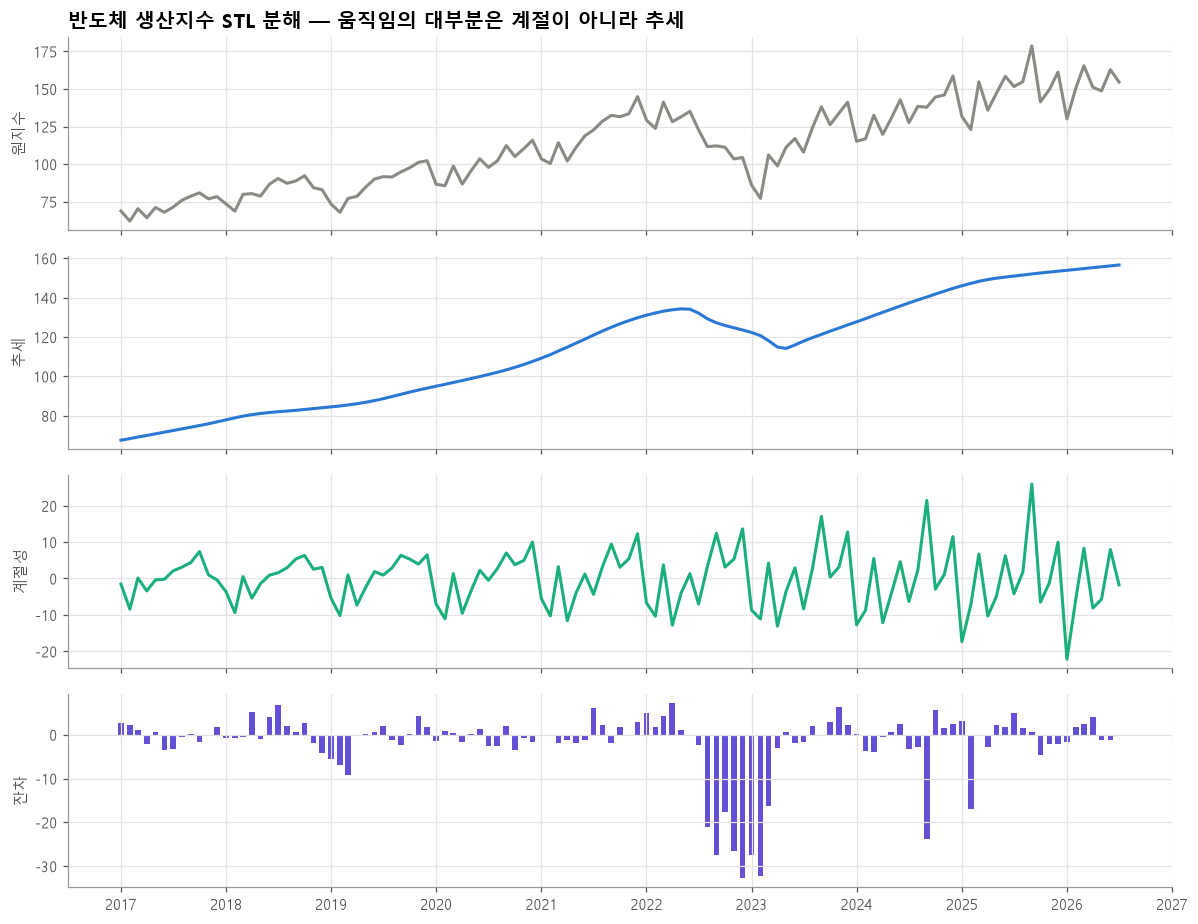

추세 범위: 67.6 ~ 156.6
계절성 진폭(최대-최소): 48.1포인트
잔차 표준편차: 7.6포인트
추세 강도 = 1 - Var(잔차)/Var(추세+잔차) = 0.92
계절성 강도 = 1 - Var(잔차)/Var(계절+잔차) = 0.44
월별 평균 계절성분: {1: -9.1, 2: -9.2, 3: 3.5, 4: -9.4, 5: -3.4, 6: 2.9, 7: -2.8, 8: 2.8, 9: 12.2, 10: 2.2, 11: 2.9, 12: 8.8}


In [13]:
stl = STL(df['semi_prod'], period=12, robust=True).fit()
comp = pd.DataFrame({'원지수': df['semi_prod'], '추세': stl.trend, '계절성': stl.seasonal, '잔차': stl.resid})
fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
for ax, col, color in zip(axes, comp.columns, [MUTED, SEMI, '#1baf7a', '#6250d6']):
    if col == '잔차':
        ax.bar(comp.index, comp[col], width=20, color=color)
    else:
        ax.plot(comp.index, comp[col], color=color, lw=2)
    ax.set_ylabel(col)
axes[0].set_title('반도체 생산지수 STL 분해 — 움직임의 대부분은 계절이 아니라 추세', loc='left')
fig.tight_layout(); fig.savefig(IMG / '06_decomposition.png', bbox_inches='tight'); plt.show()

var = lambda s: np.nanvar(s)
detrended = comp['원지수'] - comp['추세']
print(f"추세 범위: {comp['추세'].min():.1f} ~ {comp['추세'].max():.1f}")
print(f"계절성 진폭(최대-최소): {comp['계절성'].max() - comp['계절성'].min():.1f}포인트")
print(f"잔차 표준편차: {comp['잔차'].std():.1f}포인트")
print(f"추세 강도 = 1 - Var(잔차)/Var(추세+잔차) = {1 - var(comp['잔차'])/var(comp['추세']+comp['잔차']):.2f}")
print(f"계절성 강도 = 1 - Var(잔차)/Var(계절+잔차) = {1 - var(comp['잔차'])/var(comp['계절성']+comp['잔차']):.2f}")
month_season = comp['계절성'].groupby(comp.index.month).mean().round(1)
print('월별 평균 계절성분:', month_season.to_dict())

## 7. [보너스 B] 베이스라인 예측 — 단순한 방법은 어디까지 맞힐까
2025.08~2026.07(12개월)을 '모르는 미래'로 가리고, 그 이전 자료만으로 예측한다.
- **Naive**: 다음 달도 마지막 달과 같다
- **Seasonal Naive**: 올해 같은 달 = 작년 같은 달
- **Seasonal Naive + 추세**: 작년 같은 달 × (최근 12개월 평균 YoY 성장률)

정확도 경쟁이 목적이 아니라, **"과거 패턴이 반복된다"는 가정이 호황기에 얼마나 깨지는지** 보는 것이 목적이다.

최근 12개월 평균 성장배수: 1.116
                     MAE(포인트)  MAPE(%)
Naive                     8.8      5.7
Seasonal Naive           10.9      6.8
Seasonal Naive + 추세      13.0      8.5


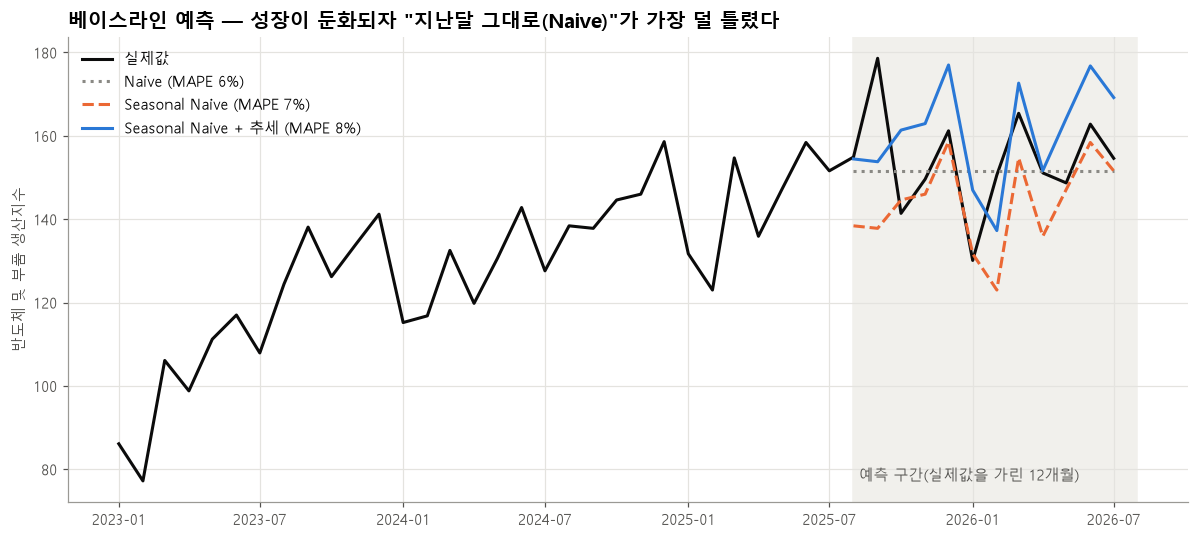

In [14]:
y = df['semi_prod']
train, test = y[:'2025-07'], y['2025-08':]
h = len(test)
fc = pd.DataFrame(index=test.index)
fc['Naive'] = train.iloc[-1]
fc['Seasonal Naive'] = y.shift(12)[test.index].values
growth = (train.iloc[-12:].values / train.iloc[-24:-12].values).mean()
fc['Seasonal Naive + 추세'] = y.shift(12)[test.index].values * growth
mae = (fc.sub(test, axis=0)).abs().mean()
mape = (fc.sub(test, axis=0)).abs().div(test, axis=0).mean() * 100
score = pd.DataFrame({'MAE(포인트)': mae, 'MAPE(%)': mape}).round(1)
print(f'최근 12개월 평균 성장배수: {growth:.3f}')
print(score)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(y['2023-01':].index, y['2023-01':], color='#0b0b0b', lw=2, label='실제값')
ax.axvspan(test.index[0], test.index[-1] + pd.offsets.MonthEnd(0), color='#f1f0ec', zorder=0)
for col, color, ls in zip(fc.columns, [MUTED, NONSEMI, SEMI], [':', '--', '-']):
    ax.plot(fc.index, fc[col], color=color, lw=2, ls=ls, label=f'{col} (MAPE {score.loc[col, "MAPE(%)"]:.0f}%)')
ax.text(test.index[0], 0.04, ' 예측 구간(실제값을 가린 12개월)', transform=ax.get_xaxis_transform(), fontsize=9.5, color='#52514e', va='bottom')
ax.set_title('베이스라인 예측 — 성장이 둔화되자 "지난달 그대로(Naive)"가 가장 덜 틀렸다', loc='left')
ax.set_ylabel('반도체 및 부품 생산지수')
ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(IMG / '07_baseline_forecast.png', bbox_inches='tight'); plt.show()

## 8. 정제 데이터 저장 (대시보드·리포트에서 재사용)

In [15]:
out = df.copy()
out.index = out.index.strftime('%Y-%m')
out.round(3).to_csv('data/clean_production.csv', encoding='utf-8-sig')
phase_tbl.round(2).to_csv('data/phase_stats.csv', encoding='utf-8-sig')
print('저장 완료:', len(out), '행')

저장 완료: 115 행
